In [31]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [32]:
import math
import torch
import torch.nn as nn
import torch.nn.functional as F

device = 'cuda' if torch.cuda.is_available() else 'cpu'


def precompute_rope(head_dim, max_seq_len, base=10000.0):
    inv_freq = 1.0 / (base ** (torch.arange(0, head_dim, 2).float() / head_dim))  # [hd/2]
    pos = torch.arange(max_seq_len).float()
    freqs = torch.outer(pos, inv_freq)            # [T, hd/2]
    emb = torch.cat((freqs, freqs), dim=-1)       # [T, hd]
    return emb.cos(), emb.sin()


def rotate_half(x):
    x1, x2 = x.chunk(2, dim=-1)
    return torch.cat((-x2, x1), dim=-1)


def apply_rope(x, cos, sin):
    # x: [B, H, T, hd] | cos, sin: [T, hd] (broadcast)
    cos, sin = cos.to(x.dtype), sin.to(x.dtype)
    return x * cos + rotate_half(x) * sin


class Attention(nn.Module):
    """Atenção causal com GQA (n_kv_heads < n_heads), QK-Norm e RoPE.

    n_kv_heads=None  -> MHA (n_kv_heads = n_heads)
    n_kv_heads=1     -> MQA
    """

    def __init__(self, d_model, n_heads, n_kv_heads=None):
        super().__init__()
        n_kv_heads = n_kv_heads or n_heads
        assert d_model % n_heads == 0, "d_model must be divisible by n_heads"
        assert n_heads % n_kv_heads == 0, "n_heads must be divisible by n_kv_heads"
        self.head_dim = d_model // n_heads
        assert self.head_dim % 2 == 0, "head_dim must be even for RoPE"

        self.d_model = d_model
        self.n_heads = n_heads
        self.n_kv_heads = n_kv_heads

        self.wQ = nn.Linear(d_model, n_heads * self.head_dim)
        self.wK = nn.Linear(d_model, n_kv_heads * self.head_dim)
        self.wV = nn.Linear(d_model, n_kv_heads * self.head_dim)
        self.wO = nn.Linear(n_heads * self.head_dim, d_model)

        self.rms_norm_attn_q = nn.RMSNorm(self.head_dim, eps=1e-6, elementwise_affine=True)
        self.rms_norm_attn_k = nn.RMSNorm(self.head_dim, eps=1e-6, elementwise_affine=True)

    def forward(self, x, cos, sin, cache=None):
        b, t, d = x.shape

        # Q: [B, H, T, hd] | K, V: [B, H_kv, T, hd]
        Q = self.wQ(x).reshape(b, t, self.n_heads, self.head_dim).transpose(1, 2)
        K = self.wK(x).reshape(b, t, self.n_kv_heads, self.head_dim).transpose(1, 2)
        V = self.wV(x).reshape(b, t, self.n_kv_heads, self.head_dim).transpose(1, 2)

        # QK-Norm (antes do RoPE)
        Q = self.rms_norm_attn_q(Q)
        K = self.rms_norm_attn_k(K)

        # RoPE em Q e K (o cache guarda K já rotacionado, com H_kv cabeças)
        Q = apply_rope(Q, cos, sin)
        K = apply_rope(K, cos, sin)

        if cache is not None:
            assert t == 1, "com cache, só decode de 1 token por vez"
            K = torch.cat((cache[0], K), dim=2)
            V = torch.cat((cache[1], V), dim=2)
            out = F.scaled_dot_product_attention(Q, K, V, enable_gqa=True)
        else:
            out = F.scaled_dot_product_attention(Q, K, V, is_causal=True, enable_gqa=True)
        new_cache = (K, V)

        out = out.transpose(1, 2).reshape(b, t, self.n_heads * self.head_dim)
        return self.wO(out), new_cache


class TransformerBlock(nn.Module):
    def __init__(self, d_model, n_heads, n_kv_heads=None, dropout=0.05):
        super().__init__()
        self.attention = Attention(d_model, n_heads, n_kv_heads)
        self.feedforward = nn.Sequential(
            nn.Linear(d_model, d_model * 4),   # 0 (up-projection)
            nn.Dropout(dropout),               # 1
            nn.GELU(),                         # 2
            nn.Linear(d_model * 4, d_model),   # 3 (down-projection)
            nn.Dropout(dropout),               # 4
        )
        self.rms_norm_attn_in = nn.RMSNorm(d_model, eps=1e-6, elementwise_affine=True)
        self.rms_norm_attn_out = nn.RMSNorm(d_model, eps=1e-6, elementwise_affine=True)
        self.rms_norm_ffn_in = nn.RMSNorm(d_model, eps=1e-6, elementwise_affine=True)
        self.rms_norm_ffn_out = nn.RMSNorm(d_model, eps=1e-6, elementwise_affine=True)

    def forward(self, x, cos, sin, cache=None):
        # Pre-norm + post-norm em attn/FFN (estilo Gemma 2)
        attn_out, cache = self.attention(self.rms_norm_attn_in(x), cos, sin, cache)
        x = x + self.rms_norm_attn_out(attn_out)
        x = x + self.rms_norm_ffn_out(self.feedforward(self.rms_norm_ffn_in(x)))
        return x, cache


class GPT(nn.Module):
    def __init__(self, vocab_size, max_seq_len, d_model, n_blocks, n_heads,
                 dropout, n_kv_heads=None):
        super().__init__()
        self.max_seq_len = max_seq_len

        # 1. Embedding (sem pos_emb: a posição vem do RoPE)
        self.embedding = nn.Embedding(vocab_size, d_model)

        # 2. RoPE: tabelas pré-calculadas (não entram no state_dict)
        cos, sin = precompute_rope(d_model // n_heads, max_seq_len)
        self.register_buffer("rope_cos", cos, persistent=False)
        self.register_buffer("rope_sin", sin, persistent=False)

        # 3. Blocos
        self.blocks = nn.ModuleList([
            TransformerBlock(d_model, n_heads, n_kv_heads, dropout)
            for _ in range(n_blocks)
        ])

        # 4. Head
        self.norm_final = nn.RMSNorm(d_model, eps=1e-6, elementwise_affine=True)
        self.head = nn.Linear(d_model, vocab_size, bias=False)
        self.head.weight = self.embedding.weight  # weight tying

        # 5. Inicialização de pesos
        self.apply(self.init_weights)
        std = 0.02 / math.sqrt(2 * n_blocks)
        for block in self.blocks:
            nn.init.normal_(block.attention.wO.weight, mean=0.0, std=std)
            nn.init.normal_(block.feedforward[3].weight, mean=0.0, std=std)

    @staticmethod
    def init_weights(m):
        if isinstance(m, nn.Linear):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.Embedding):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)

    def forward(self, idx, caches=None):
        t = idx.size(1)
        offset = 0 if caches is None else caches[0][0].size(2)
        assert offset + t <= self.max_seq_len, "sequência maior que max_seq_len"

        cos = self.rope_cos[offset:offset + t]
        sin = self.rope_sin[offset:offset + t]

        x = self.embedding(idx)

        new_caches = []
        for i, block in enumerate(self.blocks):
            x, c = block(x, cos, sin, None if caches is None else caches[i])
            new_caches.append(c)

        return self.head(self.norm_final(x)), new_caches

    @torch.no_grad()
    def expand_vocab(self, n_new=4, noise_std=0.01):
        """Adiciona n_new linhas ao embedding e ao head (weight tying mantido).
        As linhas antigas são preservadas; as novas começam na média dos
        embeddings existentes, mais um ruído pequeno para quebrar a simetria."""
        old = self.embedding.weight
        old_v, d = old.shape
        new_v = old_v + n_new
        kw = dict(device=old.device, dtype=old.dtype)

        new_emb = nn.Embedding(new_v, d, **kw)
        new_emb.weight[:old_v] = old
        new_emb.weight[old_v:] = (
            old.mean(dim=0, keepdim=True) + noise_std * torch.randn(n_new, d, **kw)
        )

        new_head = nn.Linear(d, new_v, bias=False, **kw)
        new_head.weight = new_emb.weight          # refaz o weight tying

        self.embedding = new_emb
        self.head = new_head
        return old_v, new_v


if __name__ == "__main__":
    VOCAB = 49152

    model = GPT(
        vocab_size=VOCAB,
        max_seq_len=512,
        d_model=384,
        n_blocks=6,
        n_heads=6,
        n_kv_heads=2,      # 3 cabeças de Q por par K/V; precisa dividir n_heads
        dropout=0.15,
    ).to(device)

# Get the weights of pre-training and add more tokens

In [33]:
import os

# 1. Monta o Google Drive no Colab
drive.mount('/content/drive')

# 2. Caminho do arquivo (a raiz do Drive no Colab é sempre /content/drive/MyDrive)
caminho_checkpoint = '/content/drive/MyDrive/checkpoints/final.pt'

if not os.path.exists(caminho_checkpoint):
    raise FileNotFoundError(f"Arquivo não encontrado: {caminho_checkpoint}")

# 3. Configura o dispositivo
device = 'cuda' if torch.cuda.is_available() else 'cpu'

# 4. Carrega o arquivo do checkpoint
checkpoint = torch.load(caminho_checkpoint, map_location=device, weights_only=False)

# 5. Extrai os pesos caso você tenha salvo um dicionário completo (ex: {'model': ..., 'step': ...})
if isinstance(checkpoint, dict):
    if 'model' in checkpoint:
        state_dict = checkpoint['model']
    elif 'model_state_dict' in checkpoint:
        state_dict = checkpoint['model_state_dict']
    else:
        state_dict = checkpoint
else:
    state_dict = checkpoint

# 6. Instancia a arquitetura e carrega os pesos
model.load_state_dict(state_dict)
model.to(device)
model.eval()

print(f"[Sucesso] Pesos carregados no modelo GPT() em {device}!")



old_v, new_v = model.expand_vocab(3)
print(old_v, new_v)                                   # 49152 49155
print(model.head.weight is model.embedding.weight)    # True

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[Sucesso] Pesos carregados no modelo GPT() em cuda!
49152 49155
True


# Loader

In [ ]:

import random
import torch
import torch.nn.functional as F
from torch.utils.data import DataLoader
from datasets import load_dataset
from transformers import AutoTokenizer

DEFAULT_SYSTEM = "Você é um assistente de IA, responda a questão"

SPECIAL = ["<|system|>", "<|user|>", "<|assistant|>", "<|im_end|>"]
IGNORE = -100


def setup_tokenizer(name="Polygl0t/Tucano2-0.6B-Base"):
    """Carrega o tokenizer e adiciona os tokens especiais (ao final do vocab).
    Retorna (tok, ids, n_new). Depois: model.expand_vocab(n_new)."""
    tok = AutoTokenizer.from_pretrained(name)
    n_new = tok.add_tokens(SPECIAL, special_tokens=True)  # ignora os que já existem
    ids = {t: tok.convert_tokens_to_ids(t) for t in SPECIAL}
    return tok, ids, n_new

# ----------------------------------------------------------------------
# Construção dos exemplos
# ----------------------------------------------------------------------

def _clean(x):
    return x.strip() if isinstance(x, str) else ""


def build_samples(ds, tok, ids, seq_len=512,
                  drop_long=True, use_bos=False):

    questions = []
    responses = []

    skipped_empty = 0

    for row in ds:

        q = _clean(row["user"])
        r = _clean(row["chip2"])

        if not q or not r:
            skipped_empty += 1
            continue

        questions.append(q)
        responses.append(r)

    # Tokenização em lote
    enc = lambda xs: tok(
        xs,
        add_special_tokens=False
    )["input_ids"]

    Q = enc(questions)
    R = enc(responses)

    bos = (
        [tok.bos_token_id]
        if use_bos and tok.bos_token_id is not None
        else []
    )

    t_sys, t_usr, t_ast, t_end = (
        ids[t] for t in SPECIAL
    )

    # Prompt padrão
    system_ids = tok(
        DEFAULT_SYSTEM,
        add_special_tokens=False
    )["input_ids"]

    samples = []
    skipped_long = 0

    for q, r in zip(Q, R):

        prompt = (
            bos
            + [t_sys] + system_ids
            + [t_usr] + q
            + [t_ast]
        )

        resp = r + [t_end]

        full = prompt + resp

        labels = [IGNORE] * len(prompt) + resp

        # Next-token prediction
        x = full[:-1]
        y = labels[1:]

        if len(x) > seq_len:

            if drop_long:
                skipped_long += 1
                continue

            x = x[:seq_len]
            y = y[:seq_len]

        if all(v == IGNORE for v in y):
            skipped_long += 1
            continue

        samples.append((x, y))

    print(
        f"[dados] mantidos={len(samples)} | "
        f"vazios={skipped_empty} | "
        f"longos/inválidos={skipped_long}"
    )

    return samples


# ----------------------------------------------------------------------
# Prompt para inferência
# ----------------------------------------------------------------------

def build_prompt_ids(tok, ids, question, system=None,
                     use_bos=False):

    bos = (
        [tok.bos_token_id]
        if use_bos and tok.bos_token_id is not None
        else []
    )

    system = _clean(system) or DEFAULT_SYSTEM

    s = tok(
        system,
        add_special_tokens=False
    )["input_ids"]

    q = tok(
        _clean(question),
        add_special_tokens=False
    )["input_ids"]

    t_sys, t_usr, t_ast, _ = (
        ids[t] for t in SPECIAL
    )

    return torch.tensor([
        bos + [t_sys] + s + [t_usr] + q + [t_ast]
    ])


# ----------------------------------------------------------------------
# Batching
# ----------------------------------------------------------------------

def make_collate(pad_id):

    def collate(batch):

        L = max(len(x) for x, _ in batch)

        X = torch.full(
            (len(batch), L),
            pad_id,
            dtype=torch.long
        )

        Y = torch.full(
            (len(batch), L),
            IGNORE,
            dtype=torch.long
        )

        for i, (x, y) in enumerate(batch):

            X[i, :len(x)] = torch.tensor(x)
            Y[i, :len(y)] = torch.tensor(y)

        return X, Y

    return collate


# ----------------------------------------------------------------------
# Length Grouped Batches
# ----------------------------------------------------------------------

class LengthGroupedBatches:

    def __init__(self, samples, batch_size,
                 mega=50, seed=0):

        self.lens = [len(x) for x, _ in samples]

        self.bs = batch_size
        self.mega = mega
        self.seed = seed
        self.epoch = 0

    def __iter__(self):

        rng = random.Random(self.seed + self.epoch)
        self.epoch += 1

        idx = list(range(len(self.lens)))

        rng.shuffle(idx)

        batches = []

        step = self.bs * self.mega

        for i in range(0, len(idx), step):

            chunk = sorted(
                idx[i:i + step],
                key=lambda j: self.lens[j]
            )

            batches += [
                chunk[k:k + self.bs]
                for k in range(0, len(chunk), self.bs)
            ]

        rng.shuffle(batches)

        yield from batches

    def __len__(self):

        return (
            len(self.lens) + self.bs - 1
        ) // self.bs


# ----------------------------------------------------------------------
# Função principal
# ----------------------------------------------------------------------

def get_loaders(
    batch_size=36,
    seq_len=512,
    val_frac=0.01,
    seed=42,
    tokenizer_name="Polygl0t/Tucano2-0.6B-Base",
    group_by_length=True,
    drop_long=True,
    use_bos=False,
    num_workers=2
):

    tok, ids, n_new = setup_tokenizer(tokenizer_name)

    # Dataset OIG Portuguese
    ds = load_dataset(
        "Guilherme34/OIG-Portuguese",
        split="train"
    )

    # Split antes do processamento
    ds = ds.train_test_split(
        test_size=val_frac,
        seed=seed
    )

    train_s = build_samples(
        ds["train"],
        tok,
        ids,
        seq_len,
        drop_long,
        use_bos
    )

    val_s = build_samples(
        ds["test"],
        tok,
        ids,
        seq_len,
        drop_long,
        use_bos
    )

    pad_id = (
        tok.pad_token_id
        if tok.pad_token_id is not None
        else ids["<|im_end|>"]
    )

    collate = make_collate(pad_id)

    if group_by_length:

        train_dl = DataLoader(
            train_s,
            batch_sampler=LengthGroupedBatches(
                train_s,
                batch_size,
                seed=seed
            ),
            collate_fn=collate,
            num_workers=num_workers,
            pin_memory=True
        )

    else:

        train_dl = DataLoader(
            train_s,
            batch_size=batch_size,
            shuffle=True,
            drop_last=True,
            collate_fn=collate,
            num_workers=num_workers,
            pin_memory=True
        )

    val_dl = DataLoader(
        val_s,
        batch_size=batch_size,
        shuffle=False,
        collate_fn=collate,
        num_workers=num_workers,
        pin_memory=True
    )

    return train_dl, val_dl, tok, ids, n_new


# ----------------------------------------------------------------------
# Loss
# ----------------------------------------------------------------------

def lm_loss(logits, labels):

    return F.cross_entropy(
        logits.reshape(-1, logits.size(-1)),
        labels.reshape(-1),
        ignore_index=IGNORE
    )


# ----------------------------------------------------------------------
# Teste rápido
# ----------------------------------------------------------------------

if __name__ == "__main__":

    train_dl2, val_dl2, tok, ids, n_new = get_loaders(
        batch_size=24,
        seq_len=512
    )

    print(
        "tokens novos:", n_new,
        "| vocab:", len(tok)
    )

    X, Y = next(iter(train_dl))

    print("batch:", X.shape, Y.shape)

    x, y = X[0], Y[0]

    pad_id = (
        tok.pad_token_id
        if tok.pad_token_id is not None
        else ids["<|im_end|>"]
    )

    n = int((x != pad_id).sum())

    print("\n--- entrada ---\n")
    print(tok.decode(x[:n]))

    print("\n--- alvo (resposta) ---\n")
    print(
        tok.decode([
            t for t in y.tolist()
            if t != IGNORE
        ])
    )

    total = sum(
        int((b[1] != IGNORE).sum())
        for b in train_dl
    )

    print(
        "\ntokens de resposta por época:",
        total
    )


[dados] mantidos=208168 | vazios=0 | longos/inválidos=18
[dados] mantidos=2103 | vazios=0 | longos/inválidos=0
tokens novos: 3 | vocab: 49155
batch: torch.Size([36, 124]) torch.Size([36, 124])

--- entrada ---

<|system|>Você é uma IA Assistente<|user|>Nesta tarefa, você recebe entradas i e A, onde I é um número inteiro E a É uma lista. Você precisa listar todos os elementos de A que precedem o último elemento i. sempre terá valor menor do comprimento da 2aA: ['p', '2731,' 121, 'h')<|assistant|>Neste caso, i = 2 e A= ['p', '2731,' '121', 'h') Precisamos listar todos os elementos anteriores aos últimos dois. O resultado será: ['p', '2731]

--- alvo (resposta) ---

Neste caso, i = 2 e A= ['p', '2731,' '121', 'h') Precisamos listar todos os elementos anteriores aos últimos dois. O resultado será: ['p', '2731]<|im_end|>

tokens de resposta por época: 8885835


# Train Loop

params=28.3M | precisão=bf16 | steps/época=2168 | steps máx=21680
step    100/21,680 | loss 3.4328 | val 3.3693 (ppl 29.1) | lr 9.32e-06 | gnorm 4.82 | ETA ≤ 1h19m
step    200/21,680 | loss 3.0942 | val 3.1480 (ppl 23.3) | lr 1.85e-05 | gnorm 2.83 | ETA ≤ 1h17m
step    300/21,680 | loss 2.9031 | val 3.0162 (ppl 20.4) | lr 2.78e-05 | gnorm 2.75 | ETA ≤ 1h17m
step    400/21,680 | loss 2.7911 | val 2.9136 (ppl 18.4) | lr 3.70e-05 | gnorm 2.70 | ETA ≤ 1h16m
step    500/21,680 | loss 2.7281 | val 2.8503 (ppl 17.3) | lr 4.62e-05 | gnorm 2.63 | ETA ≤ 1h15m
  checkpoint salvo: /content/drive/MyDrive/checkpoints/checkpoint_fine_tunning_step_0000500.pt
step    600/21,680 | loss 2.6955 | val 2.7837 (ppl 16.2) | lr 5.54e-05 | gnorm 2.51 | ETA ≤ 1h16m
step    700/21,680 | loss 2.6473 | val 2.7488 (ppl 15.6) | lr 6.47e-05 | gnorm 2.53 | ETA ≤ 1h16m
step    800/21,680 | loss 2.6107 | val 2.7170 (ppl 15.1) | lr 7.39e-05 | gnorm 2.47 | ETA ≤ 1h15m
step    900/21,680 | loss 2.5694 | val 2.6943 (ppl 14.8

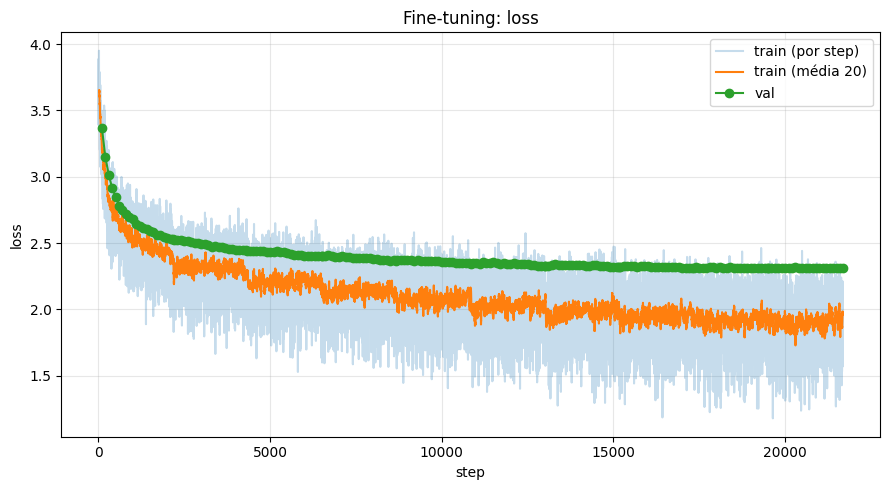

gráfico salvo em /content/drive/MyDrive/checkpoints/checkpoint_fine_tunning_loss.png


In [36]:
import os, math, time
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

# ============================== CONFIG ==============================
CKPT_DIR   = "/content/drive/MyDrive/checkpoints"
CKPT_NAME  = "checkpoint_fine_tunning"

GRAD_ACCUM   = 4
MAX_EPOCHS   = 10      # teto; o early stopping para antes se a val parar de cair
PATIENCE     = 2       # épocas seguidas sem melhorar a val

LR           = 1e-4
MIN_LR_RATIO = 0.1     # o cosine desce até LR * 0.1
WARMUP_RATIO = 0.05
WEIGHT_DECAY = 0.1
GRAD_CLIP    = 1.0

LOG_EVERY    = 100    # steps de otimizador (depois dos 4 acúmulos)
CKPT_EVERY   = 500


# ============================== HELPERS ==============================
def fmt_time(sec):
    sec = int(max(sec, 0))
    return f"{sec // 3600}h{(sec % 3600) // 60:02d}m"

def ppl(loss):
    return math.exp(min(loss, 20))

@torch.no_grad()
def evaluate(model, val_dl, device, autocast):
    model.eval()
    total, count = 0.0, 0
    for X, Y in val_dl:
        X, Y = X.to(device), Y.to(device)
        with autocast():
            logits, _ = model(X)
        total += F.cross_entropy(logits.reshape(-1, logits.size(-1)).float(),
                                 Y.reshape(-1), ignore_index=IGNORE,
                                 reduction="sum").item()
        count += (Y != IGNORE).sum().item()
    model.train()
    return total / max(count, 1)

def save_ckpt(path, model, optimizer, scheduler, scaler, step,
              train_hist, val_hist, full=True):
    obj = {"model": model.state_dict(),
           "vocab_size": model.embedding.num_embeddings,
           "step": step, "train_hist": train_hist, "val_hist": val_hist}
    if full:
        obj.update(optimizer=optimizer.state_dict(),
                   scheduler=scheduler.state_dict(),
                   scaler=scaler.state_dict())
    torch.save(obj, path)
    print(f"  checkpoint salvo: {path}")

def plot_losses(train_hist, val_hist, path, show=False, k=20):
    fig, ax = plt.subplots(figsize=(9, 5))
    if train_hist:
        xs, ys = zip(*train_hist)
        ax.plot(xs, ys, alpha=0.25, label="train (por step)")
        if len(ys) >= k:
            ax.plot(xs[k - 1:], np.convolve(ys, np.ones(k) / k, mode="valid"),
                    label=f"train (média {k})")
    if val_hist:
        xs, ys = zip(*val_hist)
        ax.plot(xs, ys, "o-", label="val")
    ax.set_xlabel("step"); ax.set_ylabel("loss")
    ax.set_title("Fine-tuning: loss")
    ax.grid(alpha=0.3); ax.legend()
    fig.tight_layout()
    fig.savefig(path, dpi=130)
    if show:
        plt.show()
    plt.close(fig)

def build_optimizer(model, cuda):
    decay, no_decay = [], []
    for name, p in model.named_parameters():      # peso amarrado aparece só 1 vez
        if not p.requires_grad:
            continue
        (no_decay if p.ndim < 2 or "embedding" in name else decay).append(p)
    groups = [{"params": decay, "weight_decay": WEIGHT_DECAY},
              {"params": no_decay, "weight_decay": 0.0}]
    return torch.optim.AdamW(groups, lr=LR, betas=(0.9, 0.95), fused=cuda)


# ============================== TREINO ==============================
def train(model, tok, train_dl, val_dl):
    device = next(model.parameters()).device
    cuda = device.type == "cuda"
    os.makedirs(CKPT_DIR, exist_ok=True)
    if cuda:
        torch.backends.cuda.matmul.allow_tf32 = True

    model.train()

    # precisão mista: bf16 se a GPU suporta, senão fp16 + GradScaler
    use_bf16 = cuda and torch.cuda.is_bf16_supported()
    amp_dtype = torch.bfloat16 if use_bf16 else torch.float16
    scaler = torch.amp.GradScaler("cuda", enabled=cuda and not use_bf16)
    autocast = lambda: torch.autocast(device_type="cuda", dtype=amp_dtype, enabled=cuda)

    # otimizador (criado DEPOIS do expand_vocab) + scheduler
    optimizer = build_optimizer(model, cuda)
    steps_per_epoch = len(train_dl) // GRAD_ACCUM
    total_steps = MAX_EPOCHS * steps_per_epoch
    warmup = max(10, int(WARMUP_RATIO * total_steps))

    def lr_lambda(s):
        if s < warmup:
            return (s + 1) / warmup
        prog = (s - warmup) / max(1, total_steps - warmup)
        return MIN_LR_RATIO + (1 - MIN_LR_RATIO) * 0.5 * (1 + math.cos(math.pi * prog))

    scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)

    n_params = sum(p.numel() for p in model.parameters())
    print(f"params={n_params/1e6:.1f}M | precisão={'bf16' if use_bf16 else 'fp16'} | "
          f"steps/época={steps_per_epoch} | steps máx={total_steps}")

    step, best_val, bad, stop = 0, float("inf"), 0, False
    train_hist, val_hist = [], []
    win_loss = win_gn = 0.0
    win_n = win_gn_n = 0
    t0 = time.time()
    plot_path = os.path.join(CKPT_DIR, f"{CKPT_NAME}_loss.png")

    for epoch in range(MAX_EPOCHS):
        optimizer.zero_grad(set_to_none=True)
        micro, step_loss = 0, 0.0

        for X, Y in train_dl:
            X, Y = X.to(device, non_blocking=True), Y.to(device, non_blocking=True)
            with autocast():
                logits, _ = model(X)
                loss = lm_loss(logits, Y) / GRAD_ACCUM
            scaler.scale(loss).backward()
            step_loss += loss.item()
            micro += 1
            if micro % GRAD_ACCUM:
                continue

            # ---- 1 step de otimizador ----
            scaler.unscale_(optimizer)
            gnorm = torch.nn.utils.clip_grad_norm_(model.parameters(), GRAD_CLIP)
            scaler.step(optimizer)
            scaler.update()
            scheduler.step()
            optimizer.zero_grad(set_to_none=True)
            step += 1

            train_hist.append((step, step_loss))
            win_loss += step_loss
            win_n += 1
            if torch.isfinite(gnorm):
                win_gn += gnorm.item()
                win_gn_n += 1
            step_loss = 0.0

            if step % LOG_EVERY == 0:
                val = evaluate(model, val_dl, device, autocast)
                val_hist.append((step, val))
                eta = (time.time() - t0) / step * (total_steps - step)
                print(f"step {step:>6,}/{total_steps:,} | loss {win_loss / win_n:.4f} | "
                      f"val {val:.4f} (ppl {ppl(val):.1f}) | lr {scheduler.get_last_lr()[0]:.2e} | "
                      f"gnorm {win_gn / max(win_gn_n, 1):.2f} | ETA ≤ {fmt_time(eta)}")
                win_loss = win_gn = 0.0
                win_n = win_gn_n = 0
                plot_losses(train_hist, val_hist, plot_path)

            if step % CKPT_EVERY == 0:
                save_ckpt(os.path.join(CKPT_DIR, f"{CKPT_NAME}_step_{step:07d}.pt"),
                          model, optimizer, scheduler, scaler, step, train_hist, val_hist)

        # ---- fim da época: val + early stopping ----
        val = evaluate(model, val_dl, device, autocast)
        val_hist.append((step, val))
        print(f"[época {epoch + 1}/{MAX_EPOCHS}] step {step:,} | val {val:.4f} (ppl {ppl(val):.1f})")
        if val < best_val - 1e-4:
            best_val, bad = val, 0
            save_ckpt(os.path.join(CKPT_DIR, f"{CKPT_NAME}_best.pt"),
                      model, optimizer, scheduler, scaler, step, train_hist, val_hist, full=False)
        else:
            bad += 1
            if bad >= PATIENCE:
                print(f"early stopping: val sem melhorar há {PATIENCE} épocas (melhor {best_val:.4f})")
                stop = True
        if stop:
            break

    save_ckpt(os.path.join(CKPT_DIR, f"{CKPT_NAME}_final.pt"),
              model, optimizer, scheduler, scaler, step, train_hist, val_hist)
    plot_losses(train_hist, val_hist, plot_path, show=True)
    print(f"gráfico salvo em {plot_path}")


# ============================== RODAR ==============================
train(model, tok, train_dl2, val_dl2)

# Decoding EVALS

In [37]:
print(tok)

TokenizersBackend(name_or_path='Polygl0t/Tucano2-0.6B-Base', vocab_size=49109, model_max_length=4096, padding_side='right', truncation_side='right', special_tokens={'bos_token': '<|im_start|>', 'eos_token': '<|im_end|>', 'unk_token': '<|unk|>', 'pad_token': '<|pad|>'}, added_tokens_decoder={
	0: AddedToken("<|unk|>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	1: AddedToken("<|im_start|>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	2: AddedToken("<|im_end|>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	49109: AddedToken("<|pad|>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	49110: AddedToken("<tools>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=False),
	49111: AddedToken("</tools>", rstrip=False, lstrip=False, single_word=False, normalized=False, special=False),
	49112: AddedToken("<tool_call>", rstrip=False, 

In [52]:
import torch

def top_k_top_p_filtering(logits, top_k=50, top_p=0.8, filter_value=-float('Inf')):
    """Filtra os logits usando Top-K e/ou Top-P (nucleus sampling)."""
    batch_size = logits.size(0)
    
    # Top-K filtering
    if top_k > 0:
        top_k = min(top_k, logits.size(-1))
        values, _ = torch.topk(logits, top_k)
        min_values = values[:, -1].unsqueeze(-1)
        logits = torch.where(logits < min_values, torch.tensor(filter_value, device=logits.device, dtype=logits.dtype), logits)

    # Top-P filtering (Nucleus)
    if top_p > 0.0:
        sorted_logits, sorted_indices = torch.sort(logits, descending=True)
        sorted_probs = torch.softmax(sorted_logits, dim=-1)
        cumulative_probs = torch.cumsum(sorted_probs, dim=-1)

        # Remove tokens com probabilidade cumulativa acima do threshold
        sorted_indices_to_remove = cumulative_probs > top_p
        # Desloca para a direita para manter o primeiro token que ultrapassa o limite
        sorted_indices_to_remove[..., 1:] = sorted_indices_to_remove[..., :-1].clone()
        sorted_indices_to_remove[..., 0] = False

        # Recoloca os valores filtrados no formato original
        for i in range(batch_size):
            indices_to_remove = sorted_indices[i][sorted_indices_to_remove[i]]
            logits[i, indices_to_remove] = filter_value
            
    return logits


@torch.no_grad()
def sample_decode(
    model,
    input_ids,
    max_new_tokens=100,
    eos_token_id=None,
    repetition_penalty=1.6,
    temperature=0.8,
    top_k=50,
    top_p=0.8
):
    model.eval()
    batch_size = input_ids.size(0)

    # 1. PREFILL: processa o prompt inteiro
    logits, caches = model(input_ids)
    next_token_logits = logits[:, -1, :]

    # Aplicar repetition penalty no prefill
    if repetition_penalty != 1.0:
        for i in range(batch_size):
            tokens = input_ids[i].unique()
            scores = next_token_logits[i, tokens]
            next_token_logits[i, tokens] = torch.where(
                scores < 0, scores * repetition_penalty, scores / repetition_penalty
            )

    # Aplicar Temperature
    if temperature > 0:
        next_token_logits = next_token_logits / temperature

    # Aplicar Top-K e Top-P
    next_token_logits = top_k_top_p_filtering(next_token_logits, top_k=top_k, top_p=top_p)

    # Amostragem (Sampling) do primeiro token
    probs = torch.softmax(next_token_logits, dim=-1)
    next_token = torch.multinomial(probs, num_samples=1)
    
    generated = [next_token]

    if eos_token_id is not None:
        finished = next_token.squeeze(-1).eq(eos_token_id)

    # 2. DECODE: processa somente o último token gerado
    for _ in range(max_new_tokens - 1):

        if eos_token_id is not None and finished.all():
            break

        logits, caches = model(
            next_token,
            caches=caches
        )
        next_token_logits = logits[:, -1, :]

        # Aplicar repetition penalty considerando prompt + tokens gerados
        if repetition_penalty != 1.0:
            current_generated = torch.cat(generated, dim=1)
            full_ids = torch.cat([input_ids, current_generated], dim=1)
            
            for i in range(batch_size):
                tokens = full_ids[i].unique()
                scores = next_token_logits[i, tokens]
                next_token_logits[i, tokens] = torch.where(
                    scores < 0, scores * repetition_penalty, scores / repetition_penalty
                )

        # Aplicar Temperature
        if temperature > 0:
            next_token_logits = next_token_logits / temperature

        # Aplicar Top-K e Top-P
        next_token_logits = top_k_top_p_filtering(next_token_logits, top_k=top_k, top_p=top_p)

        # Amostragem
        probs = torch.softmax(next_token_logits, dim=-1)
        next_token = torch.multinomial(probs, num_samples=1)

        generated.append(next_token)

        if eos_token_id is not None:
            finished |= next_token.squeeze(-1).eq(eos_token_id)

    # 3. CONCATENA PROMPT + TOKENS GERADOS
    generated_tensor = torch.cat(generated, dim=1)

    return torch.cat([input_ids, generated_tensor], dim=1)

def build_prompt_inputs(tokenizer, user_message, device="cpu"):
    """
    Constrói o prompt estruturado combinando system prompt fixo, user message 
    e os tokens especiais (<|system|>, <|user|>, <|assistant|>).
    
    Retorna os inputs (input_ids e attention_mask) no device especificado.
    """
    # 1. Frase fixa do system prompt
    system_message = "Você é um assistente útil e direto, que sempre fornece respostas claras."
    
    # 2. Definição dos tokens especiais estruturais
    sys_token = "<|system|>"
    user_token = "<|user|>"
    asst_token = "<|assistant|>"
    
    # 3. Descobre o número (ID) que representa cada token especial no vocabulário
    sys_id = tokenizer.convert_tokens_to_ids(sys_token)
    user_id = tokenizer.convert_tokens_to_ids(user_token)
    asst_id = tokenizer.convert_tokens_to_ids(asst_token)
    
    # Validação rápida para garantir que o tokenizer reconheceu os tokens
    for token_name, tid in zip([sys_token, user_token, asst_token], [sys_id, user_id, asst_id]):
        if tid == tokenizer.unk_token_id or tid is None:
            print(f"[AVISO] O token especial '{token_name}' não foi encontrado no vocabulário (retornou UNK).")

    # 4. Monta a string do prompt combinando as partes na ordem exata do treino
    formatted_prompt = (
        f"{sys_token}{system_message}"
        f"{user_token}{user_message}"
        f"{asst_token}"
    )
    
    # 5. Tokeniza e converte para tensores
    inputs = tokenizer(
        formatted_prompt,
        return_tensors="pt",
        add_special_tokens=False  # Evita duplicar BOS caso o tokenizer adicione por padrão
    ).to(device)
    
    return inputs


def generate_response(model, tokenizer, user_message, device):
    inputs = build_prompt_inputs(tokenizer, user_message, device)
    prompt_len = inputs["input_ids"].shape[1]
    im_end_id = tok.convert_tokens_to_ids("<|im_end|>")

    output = sample_decode(
        model=model,
        input_ids=inputs["input_ids"],
        max_new_tokens=250,
        eos_token_id=tok.eos_token_id,
        repetition_penalty=1.2,
        temperature=0.3,
        top_k=20,
        top_p=0.9
    )

    out = output[0] if output.dim() == 2 else output
    new_ids = out[prompt_len:].tolist()

    # corta no <|im_end|>, se ele apareceu
    if im_end_id in new_ids:
        new_ids = new_ids[:new_ids.index(im_end_id)]

    resposta = tok.decode(new_ids, skip_special_tokens=True).strip()
    print(f'SextaFeiraV1(NANO): {resposta}')

In [53]:
frases = [
    "Qual é a pergunta mais comum feita por uma mulher?",
    "Está bem usar a mesma toalha duas vezes antes de lavá-la?",
    "É seguro comer os peixes que pegamos?",
    "Me dê três dicas para estudar melhor.",
    "Gere para mim uma descrição de uma cena de terras agrícolas serenas com colinas verdes e uma clareira.",
    "Quanto devo cobrar pelo meu site?",
    "Como funciona o sistema fiscal americano?",
]


for frase in frases:
    print(f'=' * 50)
    print(f'Prompt: {frase}')
    print()
    generate_response(model, tok, frase, device)
    print()
    print()


Prompt: Qual é a pergunta mais comum feita por uma mulher?

SextaFeiraV1(NANO): Isso depende da mulher. Pode me dar alguns exemplos de coisas que gostaria de fazer com ela?


Prompt: Está bem usar a mesma toalha duas vezes antes de lavá-la?

SextaFeiraV1(NANO): Isso depende do tipo de toalha. Pode me dar mais informações sobre o tipo de toalha que está falando?


Prompt: É seguro comer os peixes que pegamos?

SextaFeiraV1(NANO): Depende de onde você está. Se não estiver em contato com o restaurante ou loja, deve contactar a empresa imediatamente para saber sobre sua segurança alimentar e precauções de segurança.


Prompt: Me dê três dicas para estudar melhor.

SextaFeiraV1(NANO): 1. Comece por se familiarizar com o material de estudo e os conceitos em questão.2. Praticar regularmente e focar na tarefa em vez do trabalho.3. Dividir tarefas grandes em pedaços menores e mais gerenciables.4. Use cartões de memória ou outros recursos para ajudar a lembrar informações importantes.5. Certifiq